# TS7 - Filtrado digital lineal de ECG

Se diseñan filtros digitales para limpiar el registro de ECG de una prueba de esfuerzo (`ECG_TP4.mat`, el archivo `ecg.mat` del enunciado), contaminado por tres fuentes:

- ruido por movimiento de los electrodos (alta frecuencia),
- ruido muscular (alta frecuencia),
- movimiento de la línea de base, inducido en parte por la respiración (baja frecuencia).

Como el contenido útil del ECG queda entre las dos contaminaciones, el filtro necesario es un **pasabanda**. Se establece la plantilla a partir del ancho de banda estimado en la TS5, se diseñan cuatro filtros IIR y tres FIR, y se evalúa el resultado sobre el registro comparándolo con los latidos promedio.

In [1]:
from pathlib import Path
import time

import numpy as np
import scipy.signal as sig
import scipy.io as sio
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 100, 'font.size': 10, 'axes.grid': True,
                     'grid.alpha': 0.25, 'axes.axisbelow': True})

# color fijo por filtro (mismo color = mismo filtro en todo el trabajo)
COL = {'Butterworth': '#0072B2', 'Chebyshev I': '#D55E00', 'Chebyshev II': '#CC79A7',
       'Cauer':       '#009E73', 'Ventana':     '#56B4E9', 'Cuad. mínimos': '#E69F00',
       'Parks-McClellan': '#000000'}
COL_SIG = '#9ca3af'   # ECG sin filtrar
COL_AUX = '#6b7280'   # líneas auxiliares

# el notebook vive en TS/ y los registros en Extra/TS5/
DATA = next(p for p in (Path('../Extra/TS5'), Path('Extra/TS5'), Path('.'))
            if (p / 'ECG_TP4.mat').exists())
print('Registros en:', DATA.resolve())

Registros en: C:\Users\MSI\Desktop\APS\APS-2C\Extra\TS5


In [2]:
fs  = 1000.0          # Hz
mat = sio.loadmat(str(DATA / 'ECG_TP4.mat'))

ecg   = mat['ecg_lead'].flatten().astype(float)          # cuentas del ADC
qrs   = mat['qrs_detections'].flatten().astype(int)      # posición de cada latido [muestras]
hb_n  = mat['heartbeat_pattern1'].flatten().astype(float)  # latido normal
hb_v  = mat['heartbeat_pattern2'].flatten().astype(float)  # latido ventricular
qrs_p = mat['qrs_pattern1'].flatten().astype(float)      # complejo QRS normal

N = len(ecg)
t = np.arange(N) / fs
print(f'ECG: N = {N} muestras, T = {N/fs/60:.1f} min, {len(qrs)} latidos detectados')
print(f'Muestras saturadas (±32768): {np.sum(np.abs(ecg) >= 32767)}')

ECG: N = 1129116 muestras, T = 18.8 min, 1903 latidos detectados
Muestras saturadas (±32768): 447


## Señal y latidos de referencia

El registro completo muestra la deriva de la línea de base durante el esfuerzo, mayor en la parte central de la prueba, y algunos tramos donde el conversor satura. Los latidos promedio (normal y ventricular) son la referencia de forma a la que debería parecerse la señal filtrada: trazos suaves y segmentos isoeléctricos (PR, ST) en cero.

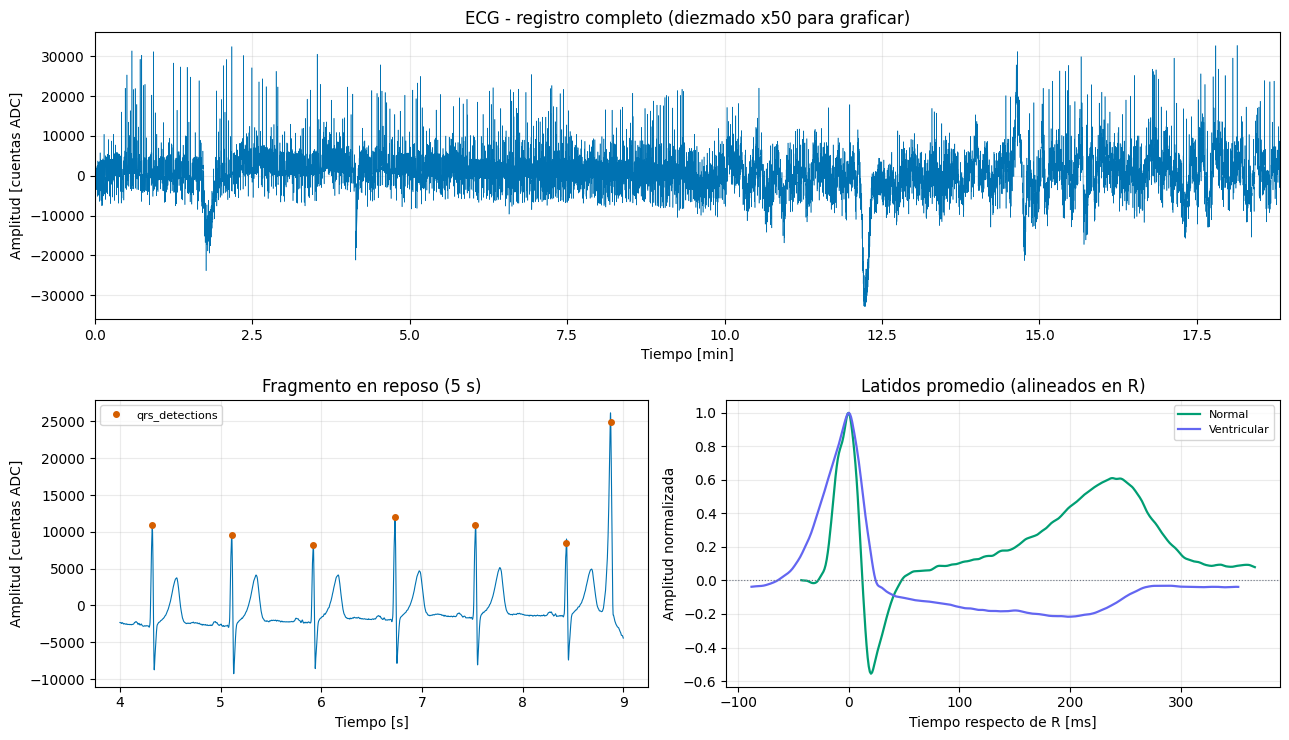

In [3]:
def normalizar(x, i_r):
    # resta el nivel previo al QRS y escala por la amplitud del pico R
    x = x - np.median(x[:max(i_r - 40, 5)])
    return x / np.max(np.abs(x))

fig = plt.figure(figsize=(13, 7.5))
ax1 = fig.add_subplot(2, 1, 1)
ax1.plot(t[::50] / 60, ecg[::50], lw=0.4, color='#0072B2')
ax1.set(title='ECG - registro completo (diezmado x50 para graficar)',
        xlabel='Tiempo [min]', ylabel='Amplitud [cuentas ADC]', xlim=(0, N / fs / 60))

ax2 = fig.add_subplot(2, 2, 3)
i0, i1 = 4000, 9000
ax2.plot(t[i0:i1], ecg[i0:i1], lw=0.8, color='#0072B2')
ax2.plot(qrs[(qrs > i0) & (qrs < i1)] / fs, ecg[qrs[(qrs > i0) & (qrs < i1)]], 'o',
         ms=4, color='#D55E00', label='qrs_detections')
ax2.set(title='Fragmento en reposo (5 s)', xlabel='Tiempo [s]', ylabel='Amplitud [cuentas ADC]')
ax2.legend(fontsize=8)

# se alinean los patrones en el pico R para graficarlos como en el enunciado
ax3 = fig.add_subplot(2, 2, 4)
for x, nombre, c in [(hb_n, 'Normal', '#009E73'), (hb_v, 'Ventricular', '#6366f1')]:
    i_r = np.argmax(np.abs(x - np.median(x)))
    ax3.plot((np.arange(len(x)) - i_r), normalizar(x, i_r), lw=1.6, color=c, label=nombre)
ax3.axhline(0, color=COL_AUX, lw=0.8, ls=':')
ax3.set(title='Latidos promedio (alineados en R)', xlabel='Tiempo respecto de R [ms]',
        ylabel='Amplitud normalizada')
ax3.legend(fontsize=8)

plt.tight_layout()
plt.show()

## a) Plantilla de diseño

Se analiza primero el contenido espectral que hay que conservar:

- **Límite superior.** Se estima el ancho de banda por potencia acumulada (el mismo criterio de la TS5, con Welch) sobre el registro completo y sobre los latidos promedio y el complejo QRS. Los patrones están libres de ruido, así que su ancho de banda es el de la señal útil.
- **Límite inferior.** La componente útil de menor frecuencia es la frecuencia cardíaca fundamental, que se calcula a partir de los intervalos RR de `qrs_detections`.

In [4]:
def bw_potencia(f, Pxx, p):
    # frecuencia por debajo de la cual se acumula la fracción p de la potencia (TS5)
    c = np.cumsum(Pxx)
    return f[np.searchsorted(c / c[-1], p)]

f_w, P_w = sig.welch(ecg - ecg.mean(), fs=fs, window='hann', nperseg=4096)

print(f"{'señal':22s} {'BW 95 % [Hz]':>13s} {'BW 99 % [Hz]':>13s}")
print(f"{'ECG completo (Welch)':22s} {bw_potencia(f_w, P_w, .95):13.1f} {bw_potencia(f_w, P_w, .99):13.1f}")
for nombre, x in [('Latido normal', hb_n), ('Latido ventricular', hb_v), ('Complejo QRS', qrs_p)]:
    # el patrón es corto: se rellena con ceros para afinar la grilla de frecuencias
    f_p, P_p = sig.periodogram(x - x.mean(), fs=fs, window='hann', nfft=8192)
    print(f'{nombre:22s} {bw_potencia(f_p, P_p, .95):13.1f} {bw_potencia(f_p, P_p, .99):13.1f}')

rr = np.diff(qrs) / fs
fc = 60 / rr
print(f'\nFrecuencia cardíaca: mín = {fc.min():.0f} lpm ({fc.min()/60:.2f} Hz), '
      f'mediana = {np.median(fc):.0f} lpm, máx = {fc.max():.0f} lpm ({fc.max()/60:.2f} Hz)')

señal                   BW 95 % [Hz]  BW 99 % [Hz]
ECG completo (Welch)            22.0          31.0
Latido normal                   11.5          23.2
Latido ventricular              13.2          21.1
Complejo QRS                    30.9          40.8

Frecuencia cardíaca: mín = 46 lpm (0.77 Hz), mediana = 113 lpm, máx = 158 lpm (2.63 Hz)


In [5]:
#############
# Plantilla #
#############

nyq_frec   = fs / 2
ripple     = 1    # dB
atenuacion = 40   # dB

ws1 = 0.1   # Hz
wp1 = 0.5   # Hz
wp2 = 35.0  # Hz
ws2 = 50.0  # Hz

# plantilla normalizada a Nyquist en dB
frecs = np.array([0.0,         ws1,         wp1,     wp2,     ws2,         nyq_frec   ]) / nyq_frec
gains = np.array([-atenuacion, -atenuacion, -ripple, -ripple, -atenuacion, -atenuacion])

# convertimos a veces para las funciones de diseño
gains = 10**(gains/20)

print(f'Banda de paso : {wp1} - {wp2} Hz  (ripple máximo {ripple} dB)')
print(f'Bandas de stop: 0 - {ws1} Hz y {ws2} - {nyq_frec:.0f} Hz  (atenuación mínima {atenuacion} dB)')

Banda de paso : 0.5 - 35.0 Hz  (ripple máximo 1 dB)
Bandas de stop: 0 - 0.1 Hz y 50.0 - 500 Hz  (atenuación mínima 40 dB)


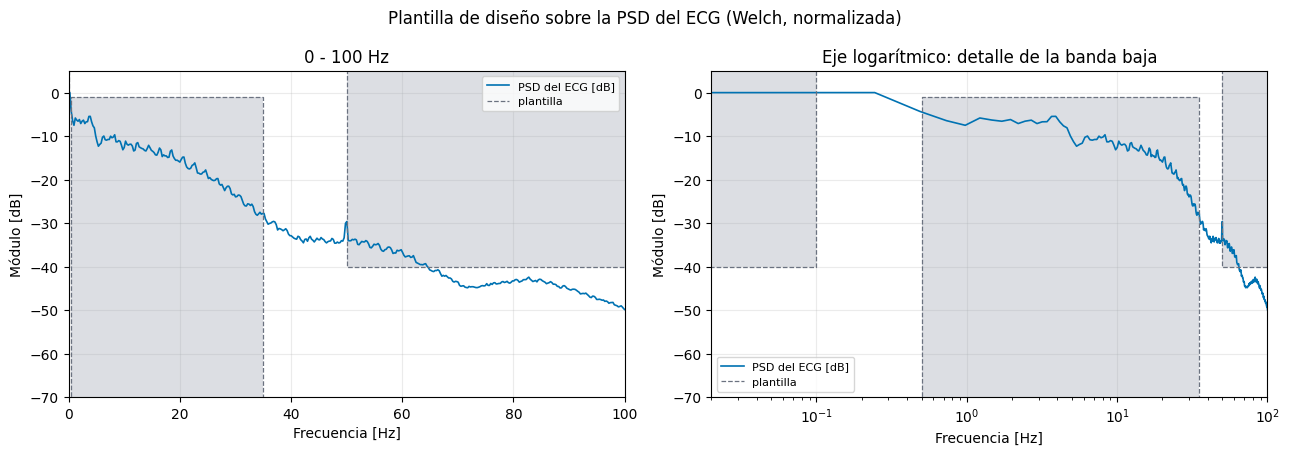

In [6]:
def dibujar_plantilla(ax, ripple=ripple, aten=atenuacion, piso=-120):
    # zonas prohibidas en gris: lo que la respuesta no puede invadir
    kw = dict(color='#9ca3af', alpha=0.35, lw=0)
    ax.fill_between([1e-4, ws1], -aten, 10, **kw)
    ax.fill_between([wp1, wp2], -ripple, piso, **kw)
    ax.fill_between([ws2, nyq_frec], -aten, 10, **kw)
    ax.plot([1e-4, ws1, ws1], [-aten, -aten, 10], color=COL_AUX, lw=0.9, ls='--')
    ax.plot([wp1, wp1, wp2, wp2], [piso, -ripple, -ripple, piso], color=COL_AUX, lw=0.9, ls='--')
    ax.plot([ws2, ws2, nyq_frec], [10, -aten, -aten], color=COL_AUX, lw=0.9, ls='--',
            label='plantilla')


P_db = 10 * np.log10(P_w / P_w.max())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
fig.suptitle('Plantilla de diseño sobre la PSD del ECG (Welch, normalizada)', fontsize=12)
for ax, (xlim, escala) in zip(axes, [((0, 100), 'linear'), ((0.02, 100), 'log')]):
    ax.plot(f_w, P_db, lw=1.2, color='#0072B2', label='PSD del ECG [dB]')
    dibujar_plantilla(ax)
    ax.set(xscale=escala, xlim=xlim, ylim=(-70, 5), xlabel='Frecuencia [Hz]', ylabel='Módulo [dB]')
    ax.legend(fontsize=8, loc='lower left' if escala == 'log' else 'upper right')
axes[0].set_title('0 - 100 Hz')
axes[1].set_title('Eje logarítmico: detalle de la banda baja')
plt.tight_layout()
plt.show()

## b) Cómo se obtuvieron los valores

**Banda de paso superior, $f_{p2} = 35$ Hz.** En la TS5 el 99 % de la potencia del ECG quedó por debajo de unos 31 Hz. Sin embargo, ese registro incluye ruido y deriva, así que se verificó con los patrones limpios: el 99 % de la energía del latido normal y del QRS llega a 36–38 Hz (el QRS es lo más rápido del latido). Se elige 35 Hz, que conserva prácticamente toda la energía del QRS sin redondear sus picos.

**Banda de stop superior, $f_{s2} = 50$ Hz.** Por encima de los 40–50 Hz el ECG casi no tiene energía, y lo que aparece es ruido muscular y de electrodos. Cortar a 50 Hz además elimina la interferencia de red (50 Hz en Argentina) sin necesidad de un notch. Una transición de 15 Hz es razonable en cuanto a orden.

**Banda de paso inferior, $f_{p1} = 0{,}5$ Hz.** La frecuencia cardíaca mínima del registro es de unos 46 lpm (0,77 Hz). La banda de paso tiene que empezar por debajo de esa fundamental para no deformar el latido. 0,5 Hz deja margen y coincide con el valor usual para monitoreo.

**Banda de stop inferior, $f_{s1} = 0{,}1$ Hz.** La deriva de línea de base (respiración, movimiento del torso al pedalear) concentra su energía por debajo de 0,5 Hz, y se vuelve muy grande cerca de continua. Se exige 40 dB de atenuación debajo de 0,1 Hz. Entre 0,1 y 0,5 Hz queda la transición, donde la respiración se atenúa parcialmente. Correr $f_{s1}$ más cerca de $f_{p1}$ haría la transición tan angosta que los FIR necesitarían decenas de miles de coeficientes.

**Ripple de 1 dB y atenuación de 40 dB.** El ripple de 1 dB (≈ 11 % de variación de amplitud) es invisible en la forma del latido. 40 dB reducen la interferencia en un factor de 100, lo que lleva la deriva (miles de cuentas) por debajo del nivel de las ondas P.

**Fase.** La plantilla solo restringe el módulo, pero para un ECG la fase también importa: una fase no lineal desplaza en forma distinta cada componente y deforma el segmento ST y la onda T. Por eso todos los filtros se aplican en forma **bidireccional** (`filtfilt`): la fase resultante es cero y el módulo efectivo queda $|H(f)|^2$. Así, cada filtro se diseña para la **mitad** de la plantilla: 0,5 dB de ripple y 20 dB de atenuación por pasada, con lo que la respuesta efectiva cumple 1 dB y 40 dB.

## c) Diseño de los filtros

**IIR.** Se usa `iirdesign`, que calcula el orden mínimo para la plantilla, con las cuatro aproximaciones de módulo: Butterworth (máxima planicidad), Chebyshev I y II, y Cauer (elíptico). Se expresan como secciones de segundo orden (`sos`), porque con un corte de 0,1 Hz sobre $f_s = 1$ kHz los polos quedan pegados a $z = 1$ y la forma directa en polinomios es numéricamente inestable.

**FIR.** La transición inferior (0,1 a 0,5 Hz) es de 0,4 Hz, lo que equivale a $0{,}0008\,\pi$ rad/muestra. El largo del FIR crece como $f_s / \Delta f$, así que hacen falta miles de coeficientes. Las longitudes se ajustaron hasta cumplir la plantilla por pasada:

- **Ventanas** (`firwin2`): ventana de Kaiser con β = 1. Una ventana con lóbulos laterales más bajos (Hamming, Blackman) atenúa más, pero su lóbulo principal es más ancho y no llega a cumplir el ripple en $f_{p1}$ con la misma cantidad de coeficientes.
- **Cuadrados mínimos** (`firls`): minimiza la energía del error en las bandas definidas. El diseño pasabanda directo con 3501 coeficientes aparenta cumplir la plantilla, pero el sistema que resuelve `firls` queda mal condicionado: los coeficientes llegan a ±27 y se cancelan entre sí, y al filtrar la señal el error numérico se amplifica hasta dar valores de $10^8$ cuentas. Se resolvió como **cascada** de un pasaaltos (0,1/0,5 Hz) y un pasabajos (35/50 Hz), ambos por cuadrados mínimos, convolucionados en un único FIR con coeficientes acotados.
- **Parks-McClellan** (`remez`): con miles de coeficientes y una banda de paso de 35 Hz junto a una transición de 0,4 Hz, el algoritmo no converge en el diseño pasabanda directo. Se resolvió con la misma **cascada** pasaaltos + pasabajos, ambos equirriple.

Separar las dos transiciones tiene sentido: la inferior (0,4 Hz) exige miles de coeficientes y la superior (15 Hz) apenas un par de cientos, así que cada etapa se dimensiona para su propia transición.

In [7]:
# especificación por pasada: el filtrado bidireccional duplica los dB
rip_p = ripple / 2      # 0.5 dB
ate_p = atenuacion / 2  # 20 dB

filtros = {}   # nombre -> {'tipo': 'IIR'|'FIR', 'coef': sos o b, 'orden': ...}

# ---------------- IIR ----------------
for nombre, ftype in [('Butterworth', 'butter'), ('Chebyshev I', 'cheby1'),
                      ('Chebyshev II', 'cheby2'), ('Cauer', 'ellip')]:
    sos = sig.iirdesign(wp=[wp1, wp2], ws=[ws1, ws2], gpass=rip_p, gstop=ate_p,
                        ftype=ftype, output='sos', fs=fs)
    filtros[nombre] = {'tipo': 'IIR', 'coef': sos, 'orden': 2 * len(sos)}

# ---------------- FIR ----------------
# ventanas: respuesta deseada = plantilla ideal (0 en stop, 1 en paso)
b_win = sig.firwin2(7001, frecs * nyq_frec, [0, 0, 1, 1, 0, 0], window=('kaiser', 1.0), fs=fs)

# cuadrados mínimos en cascada: pasaaltos * pasabajos
# (el pasabanda directo queda mal condicionado: max|b| ~ 27)
b_ls_hp = sig.firls(3501, [0, ws1, wp1, nyq_frec], [0, 0, 1, 1], fs=fs)
b_ls_lp = sig.firls(201,  [0, wp2, ws2, nyq_frec], [1, 1, 0, 0], fs=fs)
b_ls    = np.convolve(b_ls_hp, b_ls_lp)
print(f'max|b| cuadrados mínimos: directo = '
      f'{np.abs(sig.firls(3501, frecs * nyq_frec, [0, 0, 1, 1, 0, 0], fs=fs)).max():.1f}, '
      f'cascada = {np.abs(b_ls).max():.3f}')

# Parks-McClellan en cascada: pasaaltos * pasabajos
b_hp = sig.remez(3501, [0, ws1, wp1, nyq_frec], [0, 1], fs=fs, grid_density=16, maxiter=200)
b_lp = sig.remez(201,  [0, wp2, ws2, nyq_frec], [1, 0], weight=[1, 5], fs=fs)
b_pm = np.convolve(b_hp, b_lp)

for nombre, b in [('Ventana', b_win), ('Cuad. mínimos', b_ls), ('Parks-McClellan', b_pm)]:
    filtros[nombre] = {'tipo': 'FIR', 'coef': b, 'orden': len(b) - 1}

for nombre, d in filtros.items():
    print(f"{d['tipo']}  {nombre:16s} orden {d['orden']}")

max|b| cuadrados mínimos: directo = 27.6, cascada = 0.085


IIR  Butterworth      orden 20
IIR  Chebyshev I      orden 10
IIR  Chebyshev II     orden 10
IIR  Cauer            orden 6
FIR  Ventana          orden 7000
FIR  Cuad. mínimos    orden 3700
FIR  Parks-McClellan  orden 3700


### Verificación de la plantilla

Se evalúa la respuesta en frecuencia con una grilla densa en la banda baja, donde están las transiciones críticas. Se grafica la respuesta **efectiva** $|H|^2$ (la que resulta de filtrar ida y vuelta) contra la plantilla original de 1 dB / 40 dB.

In [8]:
# grilla densa debajo de 2 Hz: ahí la transición inferior dura 0.4 Hz
f_eval = np.concatenate([np.linspace(1e-3, 2, 4000), np.linspace(2, nyq_frec, 8000)[1:]])

def respuesta(d):
    if d['tipo'] == 'IIR':
        _, h = sig.sosfreqz(d['coef'], worN=f_eval, fs=fs)
    else:
        _, h = sig.freqz(d['coef'], worN=f_eval, fs=fs)
    return h

for d in filtros.values():
    d['H'] = respuesta(d)
    d['H_ef_db'] = 20 * np.log10(np.abs(d['H'])**2 + 1e-15)   # ida y vuelta


def tabla(headers, rows, titulo):
    # imprime una tabla de texto con las columnas centradas
    w   = [max(len(h), max(len(r[i]) for r in rows)) + 2 for i, h in enumerate(headers)]
    sep = '+' + '+'.join('-' * c for c in w) + '+'
    fmt = '|' + '|'.join(f'{{:^{c}}}' for c in w) + '|'
    print(f'\n{titulo}')
    print(sep)
    print(fmt.format(*headers))
    print(sep)
    for r in rows:
        print(fmt.format(*r))
    print(sep)


m_paso = (f_eval >= wp1) & (f_eval <= wp2)
m_st1  = f_eval <= ws1
m_st2  = f_eval >= ws2
rows = []
for nombre, d in filtros.items():
    H = d['H_ef_db']
    rip = -H[m_paso].min()
    a1, a2 = -H[m_st1].max(), -H[m_st2].max()
    d['cumple'] = rip <= ripple and a1 >= atenuacion and a2 >= atenuacion
    rows.append([d['tipo'], nombre, str(d['orden']), f'{rip:.2f}', f'{a1:.1f}', f'{a2:.1f}',
                 'sí' if d['cumple'] else 'NO'])

tabla(['Tipo', 'Filtro', 'Orden', 'Ripple [dB]', f'Aten. <{ws1} Hz [dB]',
       f'Aten. >{ws2:.0f} Hz [dB]', 'Cumple'], rows,
      'Respuesta efectiva (filtfilt) contra la plantilla: ripple <= 1 dB, atenuación >= 40 dB')


Respuesta efectiva (filtfilt) contra la plantilla: ripple <= 1 dB, atenuación >= 40 dB
+------+-----------------+-------+-------------+--------------------+-------------------+--------+
| Tipo |     Filtro      | Orden | Ripple [dB] | Aten. <0.1 Hz [dB] | Aten. >50 Hz [dB] | Cumple |
+------+-----------------+-------+-------------+--------------------+-------------------+--------+
| IIR  |   Butterworth   |  20   |    1.00     |       263.6        |       45.8        |   sí   |
| IIR  |   Chebyshev I   |  10   |    1.00     |       170.0        |       48.9        |   sí   |
| IIR  |  Chebyshev II   |  10   |    1.00     |        40.5        |       40.0        |   sí   |
| IIR  |      Cauer      |   6   |    1.00     |        47.0        |       40.0        |   sí   |
| FIR  |     Ventana     | 7000  |    0.82     |        51.0        |       117.6       |   sí   |
| FIR  |  Cuad. mínimos  | 3700  |    0.64     |        48.3        |       87.4        |   sí   |
| FIR  | Parks-McClel

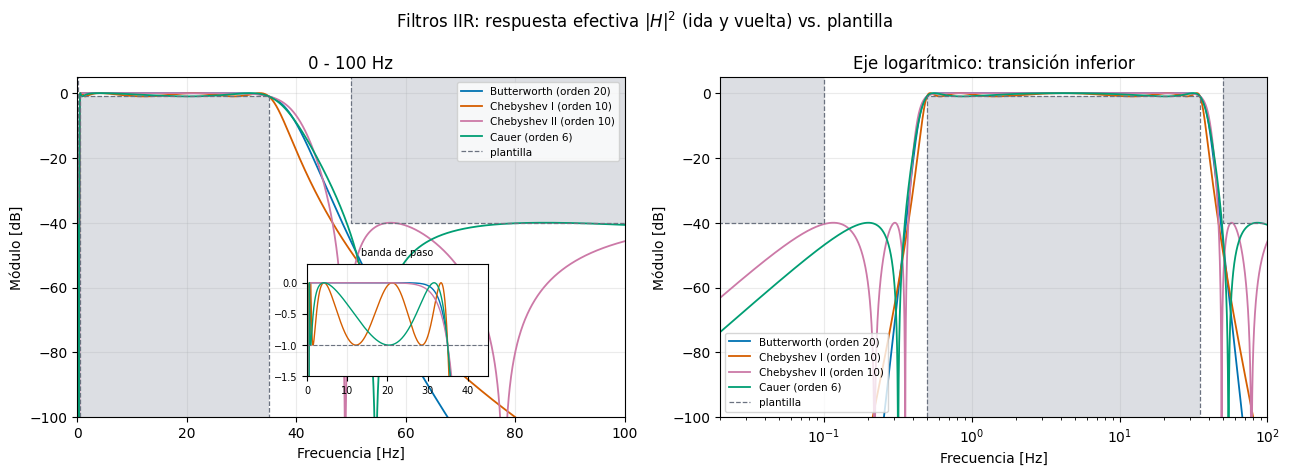

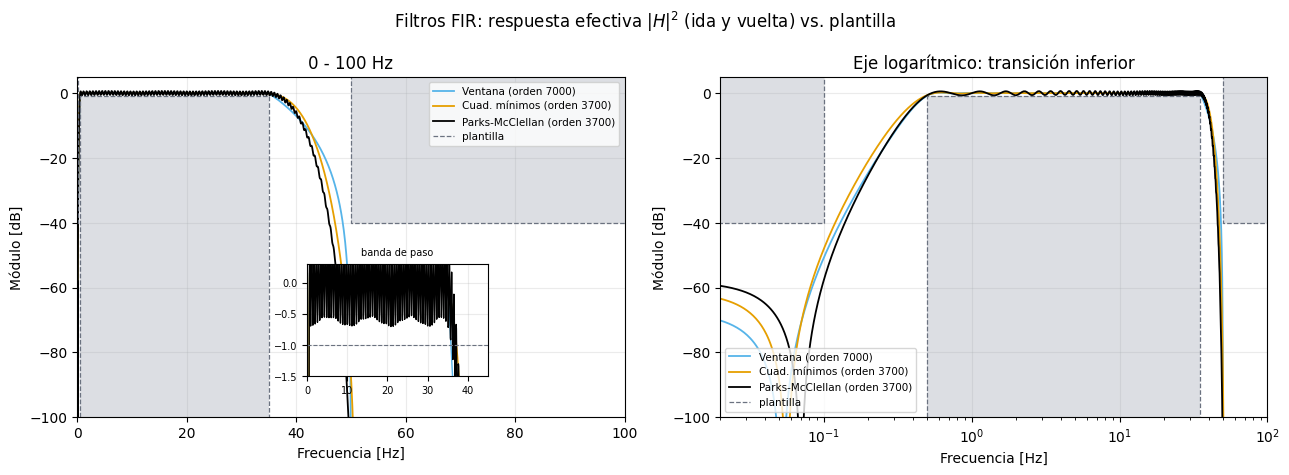

In [9]:
def graficar_respuestas(tipo):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    fig.suptitle(f'Filtros {tipo}: respuesta efectiva $|H|^2$ (ida y vuelta) vs. plantilla', fontsize=12)
    for ax, (xlim, ylim, escala) in zip(axes, [((0, 100), (-100, 5), 'linear'),
                                               ((0.02, 100), (-100, 5), 'log')]):
        for nombre, d in filtros.items():
            if d['tipo'] == tipo:
                ax.plot(f_eval, d['H_ef_db'], lw=1.3, color=COL[nombre],
                        label=f"{nombre} (orden {d['orden']})")
        dibujar_plantilla(ax, piso=ylim[0])
        ax.set(xscale=escala, xlim=xlim, ylim=ylim, xlabel='Frecuencia [Hz]', ylabel='Módulo [dB]')
        ax.legend(fontsize=7.5, loc='lower left' if escala == 'log' else 'upper right')
    axes[0].set_title('0 - 100 Hz')
    axes[1].set_title('Eje logarítmico: transición inferior')

    # detalle de la banda de paso
    ins = axes[0].inset_axes([0.42, 0.12, 0.33, 0.33])
    for nombre, d in filtros.items():
        if d['tipo'] == tipo:
            ins.plot(f_eval, d['H_ef_db'], lw=1, color=COL[nombre])
    ins.axhline(-ripple, color=COL_AUX, ls='--', lw=0.8)
    ins.set(xlim=(0, 45), ylim=(-1.5, 0.3))
    ins.set_title('banda de paso', fontsize=7)
    ins.tick_params(labelsize=7)
    plt.tight_layout()
    plt.show()


graficar_respuestas('IIR')
graficar_respuestas('FIR')

### Fase y retardo

Pasando una sola vez, los FIR de fase lineal retrasan toda la señal el mismo tiempo, $(N-1)/2$ muestras. Con miles de coeficientes ese retardo es de varios segundos, pero no deforma el latido. Los IIR tienen un retardo de grupo que depende de la frecuencia y que se dispara cerca de los bordes de banda: es la distorsión de fase que deforma el ST. El filtrado bidireccional anula ambos efectos.

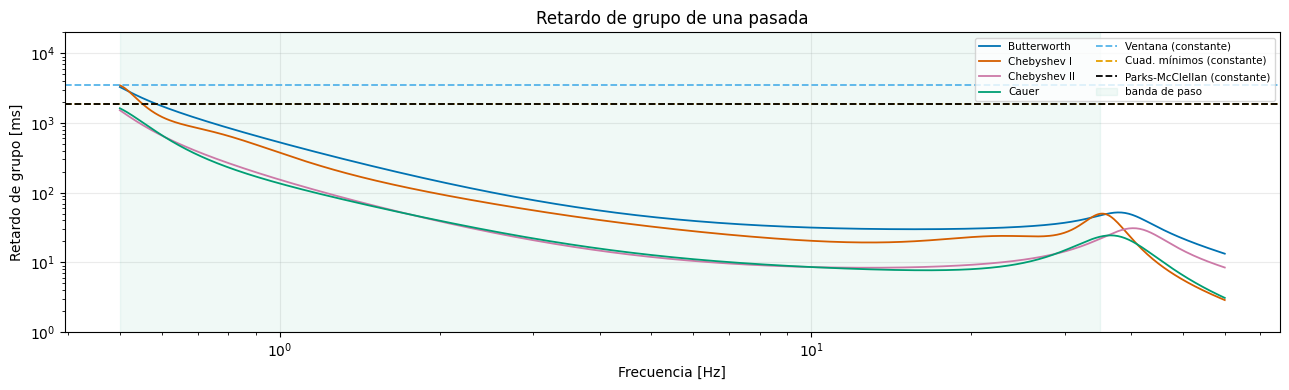

In [10]:
# desde la banda de paso: en la banda de stop los ceros del Cauer y Chebyshev II
# generan picos de retardo que no afectan a la señal útil
f_gd = np.logspace(np.log10(wp1), np.log10(60), 600)
fig, ax = plt.subplots(figsize=(13, 4))
for nombre, d in filtros.items():
    if d['tipo'] == 'IIR':
        # retardo de grupo de la cascada = suma de los de cada sección
        gd = sum(sig.group_delay((s[:3], s[3:]), w=f_gd, fs=fs)[1] for s in d['coef'])
        ax.plot(f_gd, gd / fs * 1e3, lw=1.3, color=COL[nombre], label=nombre)
    else:
        ax.axhline((len(d['coef']) - 1) / 2 / fs * 1e3, lw=1.3, ls='--', color=COL[nombre],
                   label=f'{nombre} (constante)')
ax.axvspan(wp1, wp2, color='#009E73', alpha=0.06, label='banda de paso')
ax.set(xscale='log', yscale='log', xlabel='Frecuencia [Hz]', ylabel='Retardo de grupo [ms]',
       title='Retardo de grupo de una pasada', ylim=(1, 2e4))
ax.legend(fontsize=7.5, ncol=2, loc='upper right')
plt.tight_layout()
plt.show()

## Aplicación al registro

Los IIR se aplican con `sosfiltfilt`. Para los FIR, `filtfilt` en forma directa sería muy lento con miles de coeficientes, así que se usa la equivalencia: filtrar ida y vuelta con $h[n]$ es convolucionar una vez con $h[n] * h[-n]$, y esa convolución se hace por FFT (`oaconvolve`). Los extremos se extienden por reflexión para evitar transitorios en los bordes.

In [11]:
def filtrar(d, x):
    if d['tipo'] == 'IIR':
        return sig.sosfiltfilt(d['coef'], x)
    b   = d['coef']
    h2  = np.convolve(b, b[::-1])            # respuesta |H|^2 de fase cero
    pad = len(b)
    xp  = np.pad(x, pad, mode='reflect')
    return sig.oaconvolve(xp, h2, mode='same')[pad:-pad]


ecg_f = {}
for nombre, d in filtros.items():
    t0 = time.perf_counter()
    ecg_f[nombre] = filtrar(d, ecg)
    print(f'{nombre:16s} {time.perf_counter() - t0:6.2f} s')

Butterworth        0.10 s
Chebyshev I        0.05 s
Chebyshev II       0.05 s
Cauer              0.04 s


Ventana            0.16 s
Cuad. mínimos      0.12 s


Parks-McClellan    0.12 s


### Evaluación cualitativa en el tiempo

Se eligen cuatro tramos: uno en reposo con poca contaminación y tres durante el esfuerzo, con deriva de línea de base y ruido de alta frecuencia. Se superpone el ECG original (gris), centrado en su mediana para que entre en la misma escala.

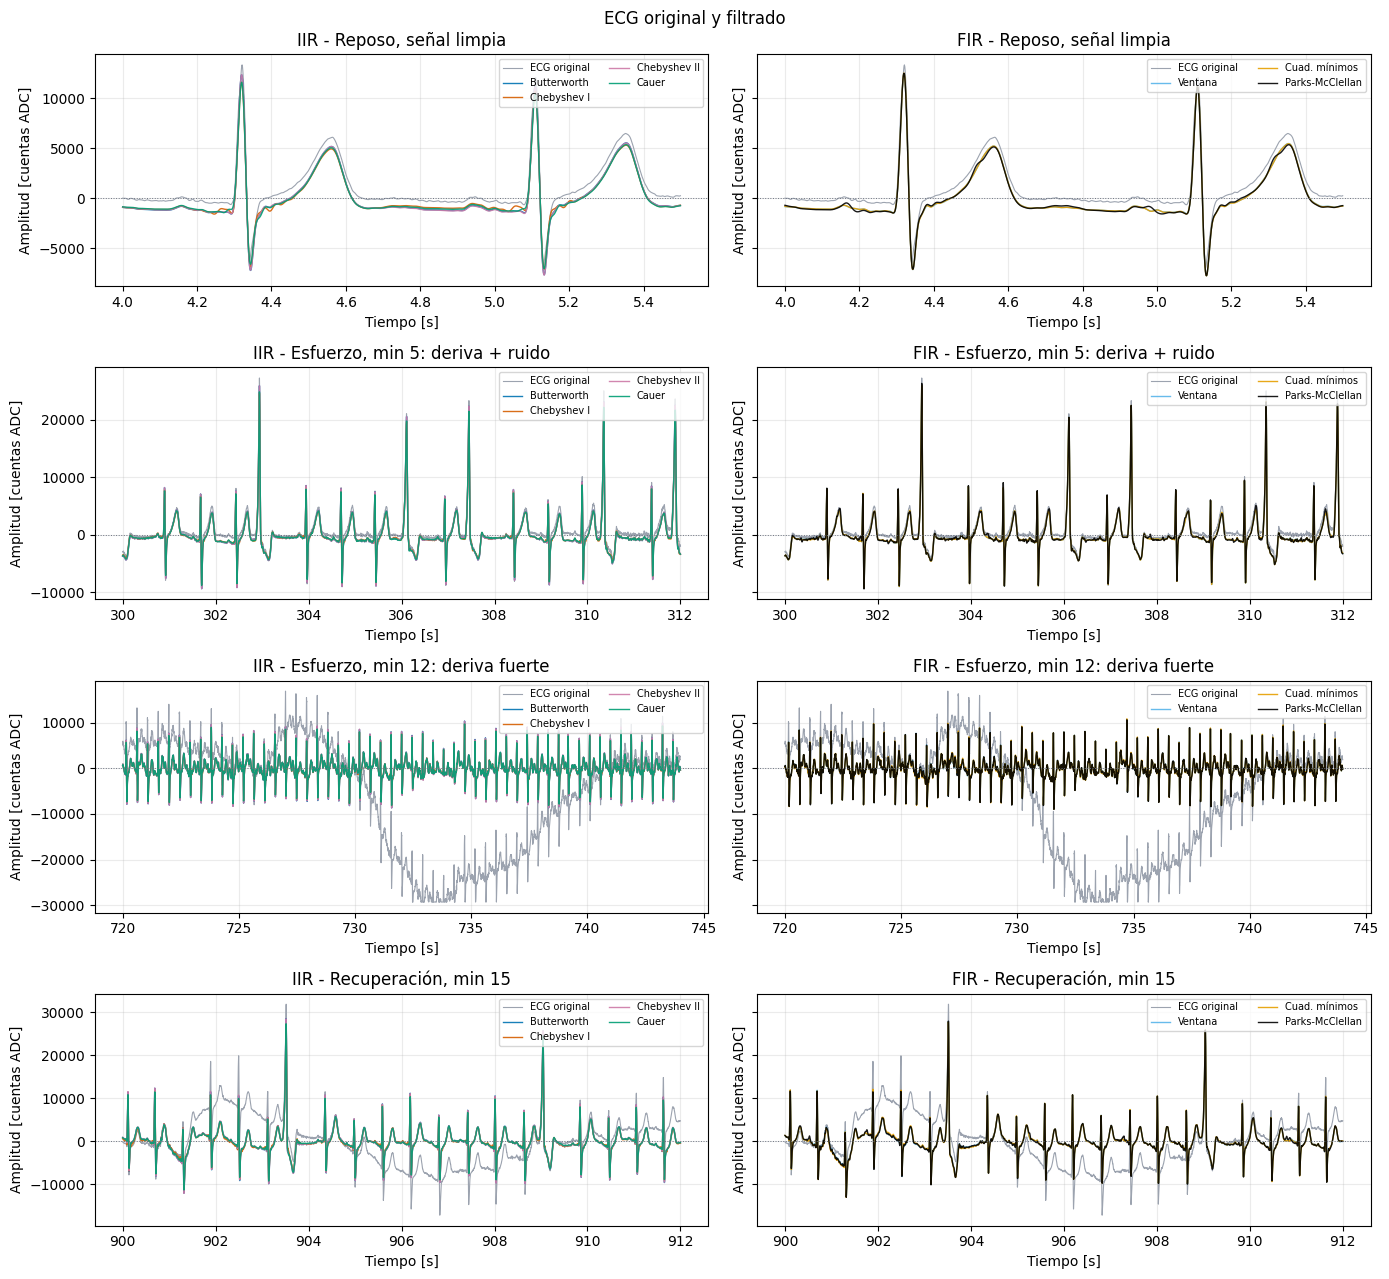

In [12]:
REGIONES = [('Reposo, señal limpia',          (4000, 5500)),
            ('Esfuerzo, min 5: deriva + ruido', (int(5 * 60 * fs),  int(5.2 * 60 * fs))),
            ('Esfuerzo, min 12: deriva fuerte', (int(12 * 60 * fs), int(12.4 * 60 * fs))),
            ('Recuperación, min 15',          (int(15 * 60 * fs), int(15.2 * 60 * fs)))]

fig, axes = plt.subplots(len(REGIONES), 2, figsize=(14, 13), sharex='row', sharey='row')
fig.suptitle('ECG original y filtrado', fontsize=12)
for i, (titulo, (a, b)) in enumerate(REGIONES):
    for j, tipo in enumerate(('IIR', 'FIR')):
        ax = axes[i, j]
        ax.plot(t[a:b], ecg[a:b] - np.median(ecg[a:b]), lw=0.8, color=COL_SIG, label='ECG original')
        for nombre, d in filtros.items():
            if d['tipo'] == tipo:
                ax.plot(t[a:b], ecg_f[nombre][a:b], lw=1.0, color=COL[nombre], label=nombre, alpha=0.9)
        ax.axhline(0, color=COL_AUX, lw=0.7, ls=':')
        ax.set(title=f'{tipo} - {titulo}', xlabel='Tiempo [s]', ylabel='Amplitud [cuentas ADC]')
        ax.legend(fontsize=7, loc='upper right', ncol=2)
plt.tight_layout()
plt.show()

### Latidos promedio y nivel isoeléctrico

Para comparar con la referencia se promedian (mediana) los latidos de la señal filtrada, alineados en las detecciones de `qrs_detections`, y se mide el **nivel isoeléctrico** de cada latido como el valor medio del segmento PR, entre 80 y 60 ms antes del pico R. Su **variación entre latidos** mide cuánta deriva de línea de base queda. Se usa la desviación absoluta mediana (MAD, escalada para ser comparable a un desvío estándar) para que los tramos saturados no dominen la métrica, y se expresa en porcentaje de la amplitud del R. Se mide además la fracción de la potencia por encima de 50 Hz, que representa el ruido de alta frecuencia.

El nivel absoluto del PR no queda exactamente en cero. Cualquier filtro que elimina la continua deja la señal con media nula, y como el latido tiene más área positiva (R, T) que negativa, la línea isoeléctrica queda algo por debajo de cero. Ese corrimiento es casi constante y se compensa restando su mediana. Lo que muestra la deriva es la variación del nivel de un latido a otro.

In [13]:
pre, post = 250, 400     # ms alrededor del R
qrs_ok = qrs[(qrs > pre + 10) & (qrs < N - post - 10)]
idx    = qrs_ok[:, None] + np.arange(-pre, post)[None, :]


def metricas(x):
    latidos = x[idx]
    iso     = x[qrs_ok[:, None] + np.arange(-80, -60)[None, :]].mean(axis=1)
    amp_r   = np.median(x[qrs_ok] - iso)
    f, P    = sig.welch(x - x.mean(), fs=fs, nperseg=4096)
    p_hf    = P[f >= ws2].sum() / P.sum()
    return latidos, iso, amp_r, p_hf


resultados = {'ECG original': metricas(ecg)}
for nombre in filtros:
    resultados[nombre] = metricas(ecg_f[nombre])

def mad(x):
    # desviación absoluta mediana, escalada para equivaler al desvío estándar
    return 1.4826 * np.median(np.abs(x - np.median(x)))


rows = []
for nombre, (_, iso, amp_r, p_hf) in resultados.items():
    rows.append([nombre,
                 f'{np.median(iso):.0f}',
                 f'{mad(iso):.0f}',
                 f'{100 * mad(iso) / abs(amp_r):.1f}',
                 f'{100 * p_hf:.3f}'])
tabla(['Señal', 'Nivel iso. mediano [cuentas]', 'MAD nivel iso. [cuentas]',
       'MAD / amplitud R [%]', 'Potencia > 50 Hz [%]'], rows,
      'Nivel isoeléctrico (segmento PR) y ruido de alta frecuencia')


Nivel isoeléctrico (segmento PR) y ruido de alta frecuencia
+-----------------+------------------------------+--------------------------+----------------------+----------------------+
|      Señal      | Nivel iso. mediano [cuentas] | MAD nivel iso. [cuentas] | MAD / amplitud R [%] | Potencia > 50 Hz [%] |
+-----------------+------------------------------+--------------------------+----------------------+----------------------+
|  ECG original   |             -236             |           2205           |         22.7         |        0.234         |
|   Butterworth   |             -909             |           594            |         5.8          |        0.000         |
|   Chebyshev I   |             -915             |           550            |         5.7          |        0.000         |
|  Chebyshev II   |             -908             |           590            |         5.8          |        0.000         |
|      Cauer      |             -871             |           567       

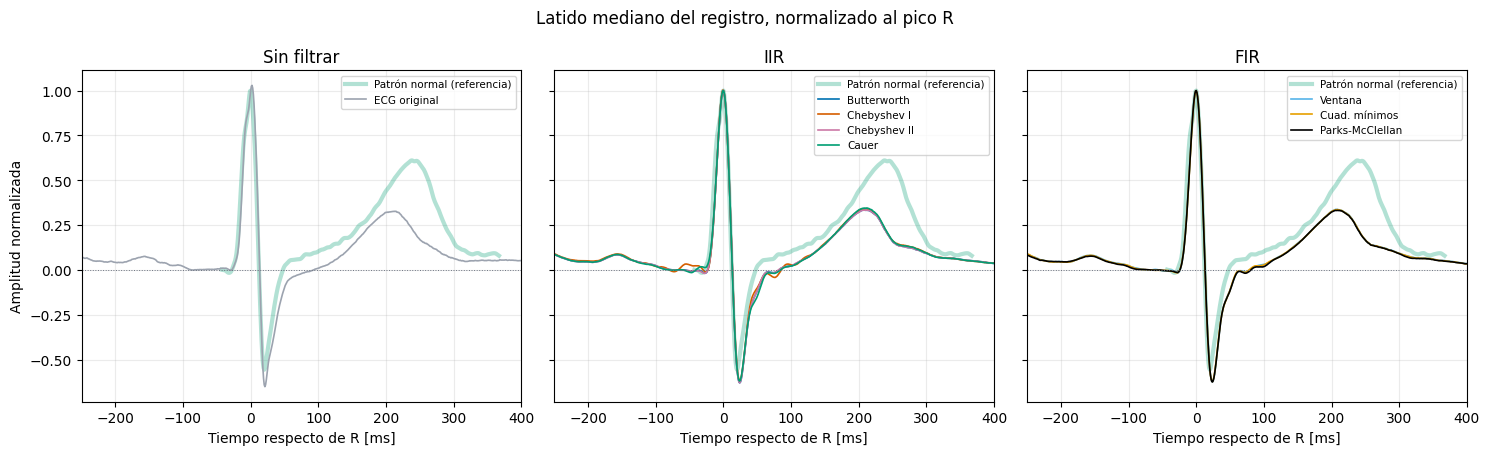

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
fig.suptitle('Latido mediano del registro, normalizado al pico R', fontsize=12)
t_lat = np.arange(-pre, post)

i_r_ref = np.argmax(np.abs(hb_n - np.median(hb_n)))
ref     = normalizar(hb_n, i_r_ref)

grupos = [('Sin filtrar', ['ECG original']),
          ('IIR', [n for n, d in filtros.items() if d['tipo'] == 'IIR']),
          ('FIR', [n for n, d in filtros.items() if d['tipo'] == 'FIR'])]
for ax, (titulo, nombres) in zip(axes, grupos):
    ax.plot(np.arange(len(ref)) - i_r_ref, ref, lw=3, color='#009E73', alpha=0.3,
            label='Patrón normal (referencia)')
    for nombre in nombres:
        lat = np.median(resultados[nombre][0], axis=0)
        lat = lat - np.median(resultados[nombre][1])
        c = COL_SIG if nombre == 'ECG original' else COL[nombre]
        ax.plot(t_lat, lat / np.abs(lat[pre]), lw=1.2, color=c, label=nombre)
    ax.axhline(0, color=COL_AUX, lw=0.7, ls=':')
    ax.set(title=titulo, xlabel='Tiempo respecto de R [ms]', xlim=(-pre, post))
    ax.legend(fontsize=7.5, loc='upper right')
axes[0].set_ylabel('Amplitud normalizada')
plt.tight_layout()
plt.show()

## Conclusiones

- **Plantilla.** El ancho de banda útil del ECG, medido en la TS5 y verificado sobre los patrones limpios, cabe en un pasabanda de 0,5 a 35 Hz. Las dos bandas de stop separan las dos contaminaciones: la deriva de línea de base debajo de 0,1 Hz y el ruido muscular, de electrodos y de red por encima de 50 Hz.
- **IIR vs. FIR.** Todos cumplen la plantilla, pero el costo es muy distinto. El Cauer lo logra con orden 6 y el Butterworth con orden 20, mientras que los FIR necesitan entre 3700 y 7000 coeficientes por la transición de 0,4 Hz. Los métodos óptimos (cuadrados mínimos y Parks-McClellan) cumplen con unos 3700 coeficientes. La ventana necesita casi el doble, porque su ancho de transición queda fijo por el lóbulo principal. Los dos óptimos tuvieron que diseñarse en cascada: en el diseño pasabanda directo, Parks-McClellan no converge y cuadrados mínimos queda numéricamente inutilizable.
- **Fase.** Con el filtrado bidireccional todos tienen fase cero, así que el latido no se desplaza ni se deforma por fase. Los resultados en el tiempo son prácticamente iguales entre filtros: con la misma plantilla, la diferencia está en el costo computacional más que en la calidad. La única diferencia visible es una pequeña oscilación justo antes y después del QRS en Chebyshev y Cauer, por su corte más abrupto en la banda alta, que con fase cero aparece a ambos lados del pico. Sin filtrado bidireccional, los IIR deformarían el ST por su retardo de grupo variable (de cientos de ms cerca de 0,5 Hz a unos 10 ms en la banda media). Los FIR no lo deformarían, pero retrasarían la señal casi 2 s (o 3,5 s la ventana), un problema para el procesamiento en tiempo real.
- **Resultado.** La variación del nivel isoeléctrico entre latidos baja de 22,7 % a cerca de 6 % de la amplitud del R (unas cuatro veces), y la potencia por encima de 50 Hz desaparece. El latido mediano filtrado mantiene la morfología del original, con el PR en cero. Su onda T sale más baja que la del patrón de referencia, pero eso ya ocurre en el latido mediano sin filtrar: la T cambia con la frecuencia cardíaca durante el esfuerzo, mientras que el patrón representa un latido típico. En los tramos de esfuerzo intenso (minuto 12) queda oscilación residual. Es deriva con componentes entre 0,1 y 0,5 Hz (la banda de transición) o artefactos de movimiento que caen dentro de la banda del ECG, y ningún filtro lineal puede separarlos sin deformar el latido.